# Journal 2 - Scoring protocol and baselines

Logbook, second part. Before any language model is trained, I want to know how a system will be judged and what the cheap alternatives achieve. The protocol (`docs/scoring_protocol.md`) was frozen on 2026-10-31 before any result existed; this notebook replays what was done with it, in order: check the scorer, score the three baselines on val, and only then touch the test sets.

## Step 1 - The scorer and its cost matrix

The decisions of the product depend on a desk (payments, disputes, technical, compliance) or on a human (`OTHER`, `UNDEFINED`). An urgent ticket sent to the wrong desk is the costly error, so the main number is an expected cost per ticket built from a small matrix of weights. I print what `src/scoring.py` uses, so that the weights are on record in this journal.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from src import scoring

print("desk of each intent:", scoring.DESK_OF_INTENT, "(OTHER and UNDEFINED -> triage)")
print("cost weights:", scoring.DEFAULT_WEIGHTS)

desk of each intent: {'payment_status': 'payments', 'dispute': 'disputes', 'technical_api': 'technical', 'compliance': 'compliance'} (OTHER and UNDEFINED -> triage)
cost weights: CostWeights(triage=1.0, wrong_desk=3.0, wrong_reference=5.0, wrong_desk_urgent=10.0)


## Step 2 - Does the scorer behave? Two trivial systems on val

Before trusting any number, I check the scorer on two systems whose result I can predict from the matrix: a system that returns exactly the true labels (every metric must be perfect, cost 0), and a system that sends every ticket to a human (`OTHER`). For the second one, the cost must be the triage weight on every ticket that has a desk and 0 on the others, which I can compute by hand from the label shares.

In [2]:
from src.dataset_build.schema import TicketLabel
val_x, val_y, val_traps = scoring.load_split(ROOT / "data/dataset/val.csv")
perfect = [json.dumps(label.model_dump()) for label in val_y]
triage = json.dumps(TicketLabel(intent="OTHER", sub_intent="OTHER", transaction_id="", amount="", currency="",
                                urgency="UNDEFINED", sentiment="UNDEFINED").model_dump())
all_triage = [triage] * len(val_y)
share_with_desk = sum(scoring.desk_of(l) != scoring.TRIAGE for l in val_y) / len(val_y)
print("val tickets:", len(val_y), "| share whose label has a desk:", round(share_with_desk, 3))
pd.DataFrame({"perfect": scoring.score(val_y, perfect), "all to a human": scoring.score(val_y, all_triage)}).loc[
    ["valid_json_rate", "desk_accuracy", "abstention_rate", "macro_f1_intent", "cost_per_ticket"]].round(3)

val tickets: 293 | share whose label has a desk: 0.833
Out[0]: 
                 perfect  all to a human
valid_json_rate    1.000           1.000
desk_accuracy      1.000           0.167
abstention_rate    0.167           1.000
macro_f1_intent    1.000           0.021
cost_per_ticket    0.000           0.833


,perfect,all to a human
valid_json_rate,1.000,1.000
desk_accuracy,1.000,0.167
abstention_rate,0.167,1.000
macro_f1_intent,1.000,0.021
cost_per_ticket,0.000,0.833


**Reading.** The perfect system gets a perfect score on every metric and a cost of 0. The system that sends everything to a human has a desk accuracy of 0.167 (exactly the share of tickets without a desk, 1 - 0.833), an abstention rate of 1 and a cost of 0.833 per ticket, which is the triage weight (1) times the 0.833 of tickets that do have a desk, as computed by hand. The scorer does what the protocol says on these two cases.

Next: the first real baselines, the two that need no learning.

## Step 3 - B0 (majority class) and B1 (keywords and regular expressions) on val

B0 predicts, for every field, the most frequent value of train: it is the floor, anything worse means a bug. B1 is the cheap option of the brief: a list of keywords per intent, a few words for urgency and tone, and regular expressions for the transaction id, the amount and the currency. B1 is written once, from the label definitions, not tuned on val. I score both on val.

In [3]:
from src.baselines import predict_majority, predict_rules, fit_tfidf, predict_tfidf
train_x, train_y, _ = scoring.load_split(ROOT / "data/dataset/train.csv")
b0 = scoring.score(val_y, predict_majority(train_y, val_x))
b1 = scoring.score(val_y, predict_rules(val_x))
SHOWN = ["desk_accuracy", "urgent_wrong_desk", "confident_and_wrong", "abstention_rate", "macro_f1_intent",
         "exact_transaction_id", "exact_amount", "accuracy_urgency", "recall_high_urgency", "cost_per_ticket"]
pd.DataFrame({"B0": b0, "B1": b1}).loc[SHOWN].round(3)

Out[0]: 
                         B0     B1
desk_accuracy         0.215  0.403
urgent_wrong_desk     0.759  0.392
confident_and_wrong   0.785  0.530
abstention_rate       0.000  0.266
macro_f1_intent       0.059  0.321
exact_transaction_id  0.648  0.894
exact_amount          0.642  0.829
accuracy_urgency      0.471  0.464
recall_high_urgency   0.000  0.203
cost_per_ticket       3.925  2.509


,B0,B1
desk_accuracy,0.215,0.403
urgent_wrong_desk,0.759,0.392
confident_and_wrong,0.785,0.530
abstention_rate,0.000,0.266
macro_f1_intent,0.059,0.321
exact_transaction_id,0.648,0.894
exact_amount,0.642,0.829
accuracy_urgency,0.471,0.464
recall_high_urgency,0.000,0.203
cost_per_ticket,3.925,2.509


## Step 4 - B2 (TF-IDF and logistic regression), regularisation chosen on val

B2 trains one logistic regression per classified field on word and word-pair TF-IDF features of the train tickets. It cannot classify the reference fields, so it reuses the regular expressions of B1 for them. The only setting is the regularisation strength C; the protocol says baselines are tuned on val only, so I try four values on val and keep the one with the lowest cost per ticket.

In [4]:
rows = []
for c in (0.3, 1.0, 3.0, 10.0):
    result = scoring.score(val_y, predict_tfidf(fit_tfidf(train_x, train_y, c), val_x))
    rows.append({"C": c, "cost_per_ticket": result["cost_per_ticket"], "desk_accuracy": result["desk_accuracy"],
                 "macro_f1_intent": result["macro_f1_intent"]})
grid = pd.DataFrame(rows).set_index("C").round(3)
display(grid)
best_c = grid["cost_per_ticket"].idxmin()
b2 = scoring.score(val_y, predict_tfidf(fit_tfidf(train_x, train_y, best_c), val_x))
print("kept C =", best_c)
pd.DataFrame({"B0": b0, "B1": b1, "B2": b2}).loc[SHOWN].round(3)

      cost_per_ticket  desk_accuracy  macro_f1_intent
C                                                    
0.3             1.874          0.853            0.741
1.0             1.631          0.918            0.881
3.0             1.519          0.935            0.914
10.0            1.478          0.949            0.927
kept C = 10.0
Out[0]: 
                         B0     B1     B2
desk_accuracy         0.215  0.403  0.949
urgent_wrong_desk     0.759  0.392  0.076
confident_and_wrong   0.785  0.530  0.051
abstention_rate       0.000  0.266  0.137
macro_f1_intent       0.059  0.321  0.927
exact_transaction_id  0.648  0.894  0.894
exact_amount          0.642  0.829  0.829
accuracy_urgency      0.471  0.464  0.952
recall_high_urgency   0.000  0.203  0.911
cost_per_ticket       3.925  2.509  1.478


,B0,B1,B2
desk_accuracy,0.215,0.403,0.949
urgent_wrong_desk,0.759,0.392,0.076
confident_and_wrong,0.785,0.530,0.051
abstention_rate,0.000,0.266,0.137
macro_f1_intent,0.059,0.321,0.927
exact_transaction_id,0.648,0.894,0.894
exact_amount,0.642,0.829,0.829
accuracy_urgency,0.471,0.464,0.952
recall_high_urgency,0.000,0.203,0.911
cost_per_ticket,3.925,2.509,1.478


**Reading.** B0 is the floor, as it should be: cost 3.925 per ticket, no urgent ticket recognised (recall 0) and 0.759 of the urgent tickets sent to a wrong desk. Its exact match on `transaction_id` and `amount` (0.65) is just the share of tickets that have none, since the majority value is the empty string.

B1 brings the cost to 2.509. It extracts the references well (0.894 for the id, 0.829 for the amount, against 0.65 for always answering empty) but it is poor at the rest: desk accuracy 0.403, a quarter of the tickets sent to a human because no keyword matched, and urgency accuracy of 0.464, no better than B0's 0.471, so the urgency keywords do not help.

For B2, the cost falls as C grows (1.874, 1.631, 1.519, 1.478) and the best value is the largest of the four I tried, so the optimum may lie beyond 10. I do not extend the grid: the protocol fixed four values in advance, and 1.478 is already a strong, cheap result. B2 reaches 0.949 desk accuracy, 0.952 urgency accuracy and 0.911 recall on urgent tickets, and sends only 0.076 of the urgent tickets to a wrong desk. On the reference fields it is identical to B1 (0.894 and 0.829) because it reuses the same regular expressions: that is the room left for a model that reads the text.

The settings are now fixed (C = 10). The dataset is final and the protocol says the test sets are read once, so the next step is that single reading.

## Step 5 - The baselines on test_natural (read once)

`test_natural` holds 610 tickets in the natural mix and carries all the headline numbers. I score B0, B1 and B2 (fitted on train, C = 10) on it and compare each with the best baseline using a paired bootstrap: the same tickets are resampled for both systems, 2000 times, and I report the mean difference in cost per ticket with its 95 percent interval.

In [5]:
nat_x, nat_y, _ = scoring.load_split(ROOT / "data/dataset/test_natural.csv")
models = fit_tfidf(train_x, train_y, 10.0)
preds = {"B0": predict_majority(train_y, nat_x), "B1": predict_rules(nat_x), "B2": predict_tfidf(models, nat_x)}
results = {name: scoring.score(nat_y, raws) for name, raws in preds.items()}
display(pd.DataFrame(results).loc[SHOWN].round(3))
for name in ("B0", "B1"):
    mean, low, high = scoring.paired_bootstrap(scoring.costs(nat_y, preds[name]), scoring.costs(nat_y, preds["B2"]))
    print(f"cost {name} - B2: {mean:.3f}  95% interval [{low:.3f}, {high:.3f}]")

                         B0     B1     B2
desk_accuracy         0.236  0.446  0.916
urgent_wrong_desk     0.778  0.335  0.066
confident_and_wrong   0.764  0.457  0.089
abstention_rate       0.000  0.315  0.095
macro_f1_intent       0.064  0.357  0.871
exact_transaction_id  0.648  0.895  0.895
exact_amount          0.633  0.802  0.802
accuracy_urgency      0.500  0.454  0.930
recall_high_urgency   0.000  0.096  0.892
cost_per_ticket       3.890  2.274  1.666
cost B0 - B2: 2.225  95% interval [1.936, 2.515]
cost B1 - B2: 0.608  95% interval [0.374, 0.846]


### Visual Analysis — Baselines Comparison on `test_natural` (610 tickets)


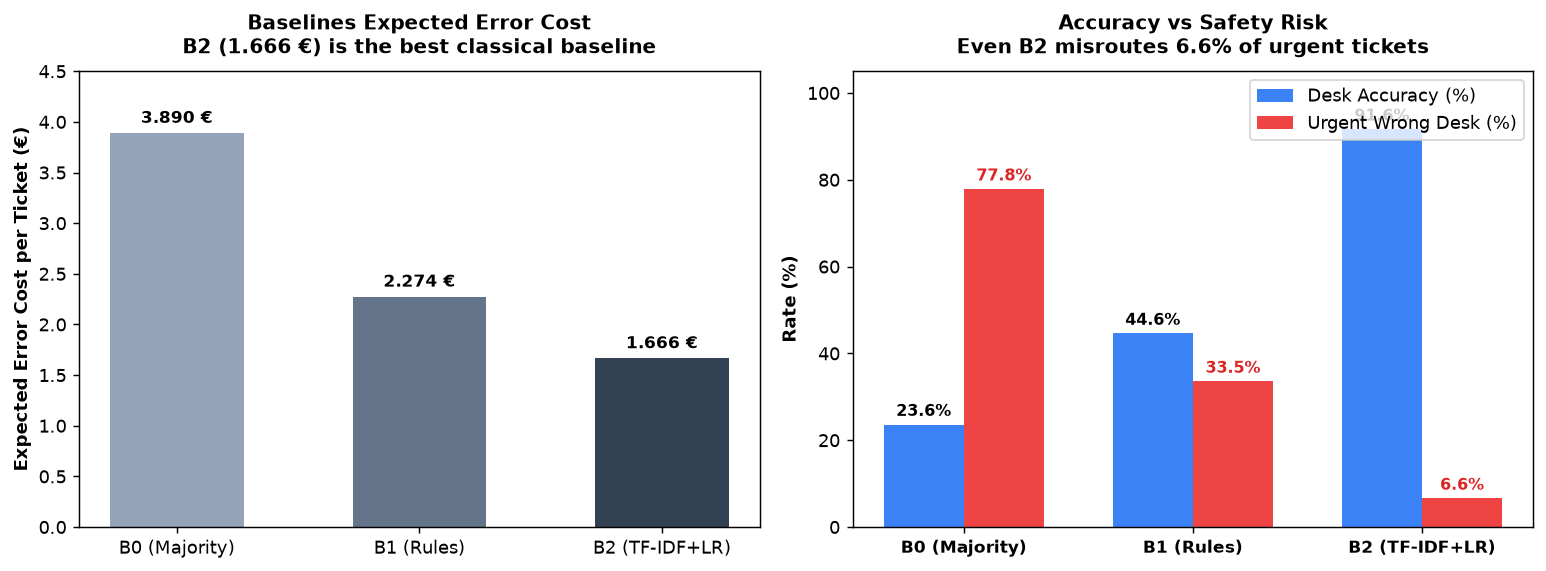

In [6]:
import matplotlib.pyplot as plt
import numpy as np

b_names = ["B0 (Majority)", "B1 (Rules)", "B2 (TF-IDF+LR)"]
b_keys = ["B0", "B1", "B2"]
b_costs = [results[k]["cost_per_ticket"] for k in b_keys]
b_acc = [results[k]["desk_accuracy"] * 100 for k in b_keys]
b_urgent = [results[k]["urgent_wrong_desk"] * 100 for k in b_keys]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Subplot 1: Error Cost
bars1 = ax1.bar(b_names, b_costs, color=["#94a3b8", "#64748b", "#334155"], width=0.55)
ax1.set_ylabel("Expected Error Cost per Ticket (€)", fontsize=10, fontweight="bold")
ax1.set_title("Baselines Expected Error Cost\nB2 (1.666 €) is the best classical baseline", fontsize=11, fontweight="bold", pad=10)
ax1.set_ylim(0, 4.5)

for bar, c in zip(bars1, b_costs):
    ax1.text(bar.get_x() + bar.get_width()/2, c + 0.1, f"{c:.3f} €", ha="center", fontsize=9.5, fontweight="bold")

# Subplot 2: Desk Accuracy vs Urgent Misrouting
x = np.arange(len(b_names))
w = 0.35
ax2.bar(x - w/2, b_acc, w, label="Desk Accuracy (%)", color="#3b82f6")
ax2.bar(x + w/2, b_urgent, w, label="Urgent Wrong Desk (%)", color="#ef4444")
ax2.set_ylabel("Rate (%)", fontsize=10, fontweight="bold")
ax2.set_title("Accuracy vs Safety Risk\nEven B2 misroutes 6.6% of urgent tickets", fontsize=11, fontweight="bold", pad=10)
ax2.set_xticks(x)
ax2.set_xticklabels(b_names, fontsize=9.5, fontweight="bold")
ax2.set_ylim(0, 105)
ax2.legend(frameon=True, loc="upper right")

for i in range(len(b_names)):
    ax2.text(x[i] - w/2, b_acc[i] + 2, f"{b_acc[i]:.1f}%", ha="center", fontsize=9, fontweight="bold")
    ax2.text(x[i] + w/2, b_urgent[i] + 2, f"{b_urgent[i]:.1f}%", ha="center", fontsize=9, fontweight="bold", color="#dc2626")

plt.tight_layout()
plt.show()



**Reading.** On the 610 tickets of test_natural the order is the same as on val: B2 costs 1.666 per ticket, B1 2.274 and B0 3.890. Paired on the same tickets, B0 costs 2.225 more than B2 (interval 1.936 to 2.515) and B1 costs 0.608 more (interval 0.374 to 0.846); both intervals exclude 0, so B2 is better than the two others and not by chance. B2 is a little less good on test than on val (desk accuracy 0.916 against 0.949), as expected for tickets written by another model; the baselines were fitted and tuned without seeing them. The reference fields are again identical for B1 and B2 (0.895 for the id, 0.802 for the amount), since they share the same regular expressions.

B2 is therefore the baseline to beat, and any model of this project is compared with it, with the same bootstrap.


## Step 6 - The traps (test_traps), per trap type

`test_traps` has at least 20 tickets per trap type by design (at most 380 tickets here, with some types below 20) and is never an overall score: it shows where a system breaks. For B1 and B2 I compute, per trap type, the desk accuracy and the cost per ticket, and I print the number of tickets, since several types are below 20.

                          n  desk_accuracy_B1  ...  cost_B1  cost_B2
currency_missing       30.0              0.30  ...     3.50     5.10
id_split_lines          6.0              0.67  ...     3.67     5.00
id_lowercase           24.0              0.21  ...     2.67     5.00
id_spaced              26.0              0.42  ...     3.46     4.85
amount_two_equal       13.0              0.38  ...     4.62     4.62
currency_lone_dollar   16.0              0.06  ...     3.06     4.56
id_bare_with_intro     22.0              0.18  ...     3.86     4.55
id_malformed           24.0              0.38  ...     3.92     4.50
id_nohyphen            18.0              0.28  ...     3.56     4.39
id_two_equal           16.0              0.56  ...     3.44     4.31
amount_approx          28.0              0.50  ...     4.32     3.39
amount_two_main        23.0              0.26  ...     3.61     3.04
amount_k_suffix        34.0              0.24  ...     2.76     3.03
other_language         20.0       

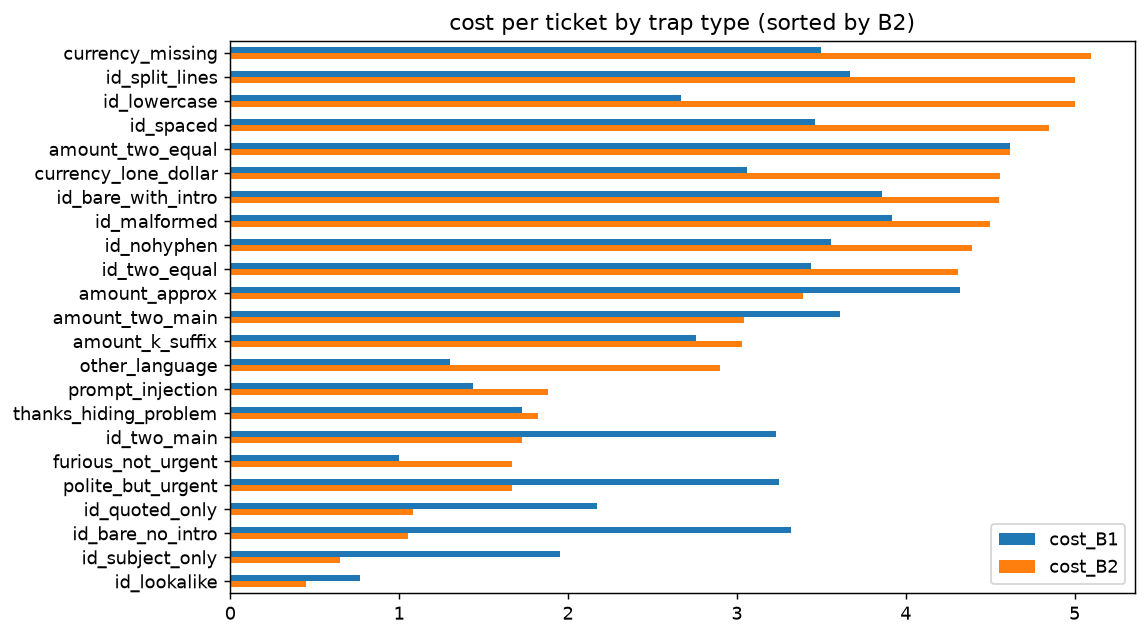

In [7]:
trap_x, trap_y, trap_tags = scoring.load_split(ROOT / "data/dataset/test_traps.csv")
tables = {}
for name, predictor in (("B1", predict_rules), ("B2", lambda x: predict_tfidf(models, x))):
    table = scoring.by_trap(trap_y, predictor(trap_x), trap_tags)
    tables[name] = pd.DataFrame(table, index=["n", "desk_accuracy", "cost"]).T
both = tables["B1"].add_suffix("_B1").join(tables["B2"].add_suffix("_B2"))[["n_B1", "desk_accuracy_B1", "desk_accuracy_B2", "cost_B1", "cost_B2"]]
both = both.rename(columns={"n_B1": "n"}).round(2).sort_values("cost_B2", ascending=False)
display(both)
fig, ax = plt.subplots(figsize=(9, 5))
both[["cost_B1", "cost_B2"]].plot.barh(ax=ax, title="cost per ticket by trap type (sorted by B2)")
ax.invert_yaxis(); plt.tight_layout()

### Visual Analysis — Where Classical ML Breaks: Top Vulnerabilities of Baseline B2


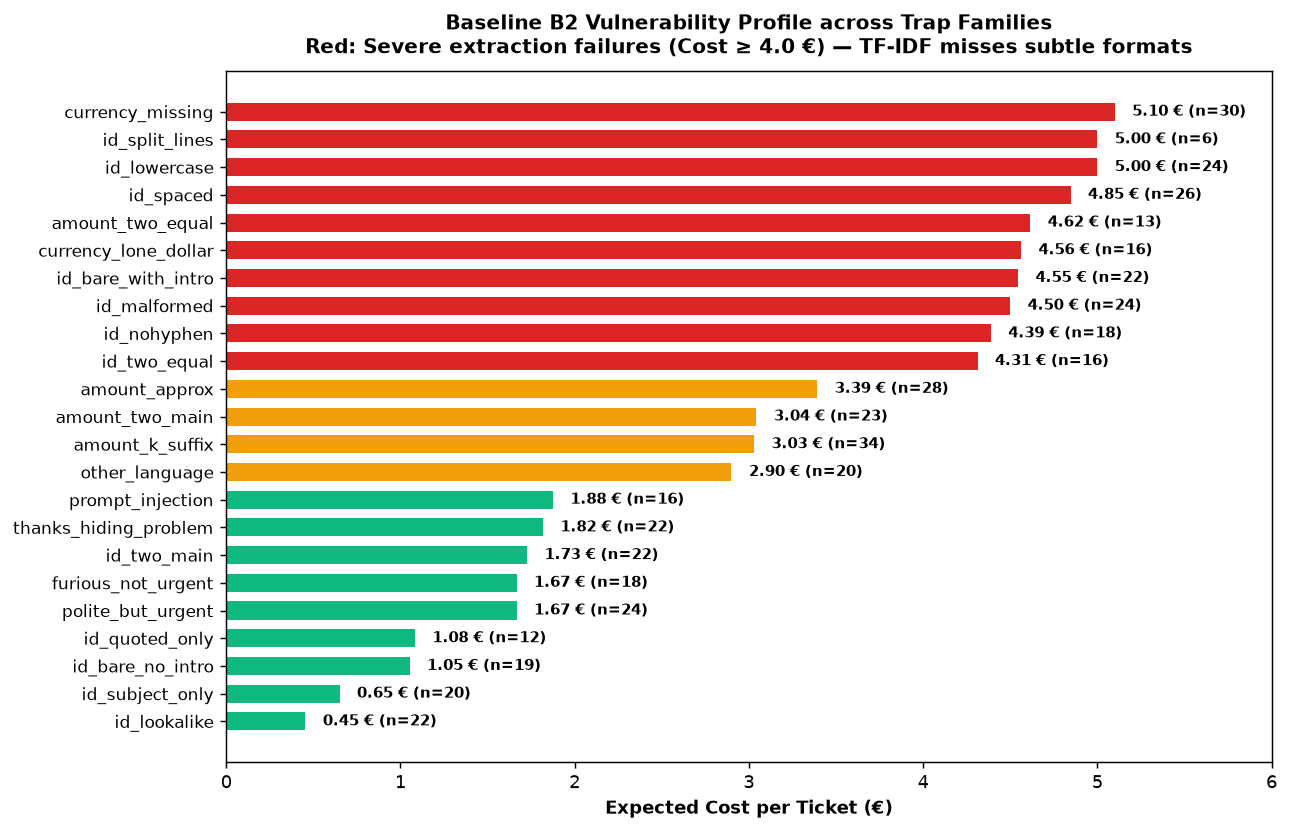

In [8]:
import numpy as np

df_b2_traps = tables["B2"].sort_values("cost", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6.5))
y_pos = np.arange(len(df_b2_traps))
costs_t = df_b2_traps["cost"].values
colors = ["#dc2626" if c >= 4.0 else "#f59e0b" if c >= 2.0 else "#10b981" for c in costs_t]

bars = ax.barh(y_pos, costs_t, color=colors, height=0.65)
ax.set_yticks(y_pos)
ax.set_yticklabels(df_b2_traps.index, fontsize=9.5)
ax.set_xlabel("Expected Cost per Ticket (€)", fontsize=10, fontweight="bold")
ax.set_title("Baseline B2 Vulnerability Profile across Trap Families\nRed: Severe extraction failures (Cost ≥ 4.0 €) — TF-IDF misses subtle formats", fontsize=11, fontweight="bold", pad=10)
ax.set_xlim(0, 6.0)

for bar, c, n in zip(bars, costs_t, df_b2_traps["n"].astype(int)):
    ax.text(c + 0.1, bar.get_y() + bar.get_height()/2, f"{c:.2f} € (n={n})", va="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.show()



**Reading.** For B2, desk accuracy is high on almost every trap type (0.83 to 1.00), the exception being `other_language` (0.55): a classifier trained on French and English tickets does not carry over to German, Spanish or Italian. Yet the cost per ticket of B2 is above 4 on many types (`currency_missing` 5.10, `id_split_lines` 5.00, `id_lowercase` 5.00, `id_spaced` 4.85, `amount_two_equal` 4.62...) while its desk is right: these are the types where the reference fields are wrong, and the matrix charges 5 for a wrong id, amount or currency on a ticket with a desk. So the traps that hurt B2 are extraction traps (an id written in lowercase or split over two lines, a missing currency, two amounts), not routing traps. B1 is worse on both counts.

Several types have fewer than 20 tickets (6 for `id_split_lines`, 12 for `id_quoted_only`, 13 for `amount_two_equal`), so these rows are counts with their denominator, not rates to compare finely.

**State at the end of this journal.** The cheapest strong option, B2, costs 1.666 per ticket on test_natural with almost no infrastructure, and what it misses is the extraction of references in unusual forms and tickets in other languages. A fine-tuned model has to beat 1.666 with an interval that excludes 0, keep valid JSON at 99 percent or more, and not send more urgent tickets to a wrong desk than B2 (0.066). Next journal: the training on Vertex, from the smoke runs to the full run.
